In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from plotnine import *
from pyhere import here
import itertools
import seaborn as sns

In [2]:
phot = pd.read_csv(here('data/cleaned', 'MIRION_cleaned_everything.csv'))

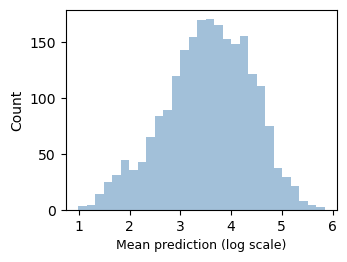

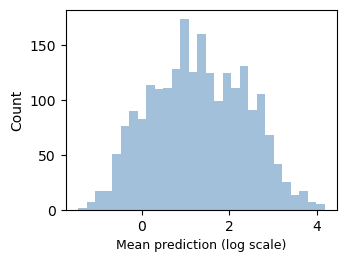

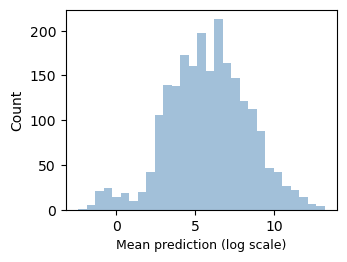

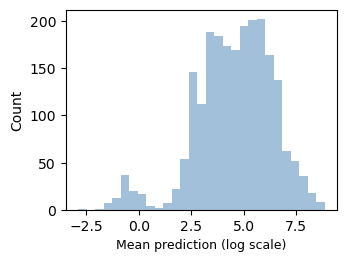

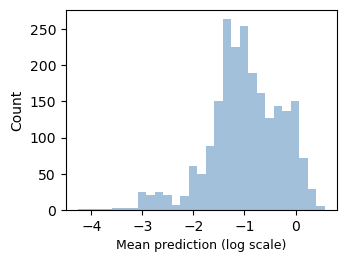

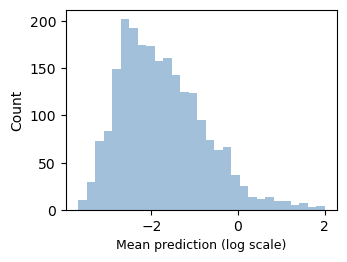

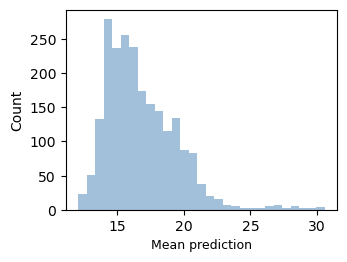

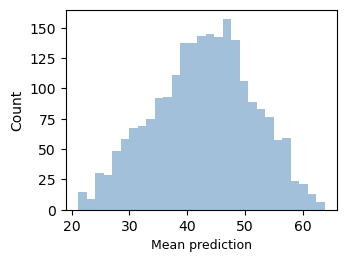

In [15]:
for response in ["LRATIO", "LM", "L_BOL", "MASS", "DIAM", "SURF_DENS", "TEMP", "T_BOL"]:
    data = pd.read_csv(here('predictions', f'{response}_final_predictions.csv'))

    if response == 'TEMP' or response == 'T_BOL':
        pred_data = data['mean_pred']
    else:
        pred_data = np.log(data['mean_pred'])

    bins = np.linspace(min(pred_data), max(pred_data), 30)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    plt.hist(pred_data, bins=bins, color='steelblue', alpha=0.5, label='Predicted')

    if response == 'TEMP' or response == 'T_BOL':
        # plt.title(f'{response} Prediction Distribution')
        plt.xlabel('Mean prediction', fontsize=9)
    else:
        # plt.title(f'{response} Log Prediction Distribution')
        plt.xlabel('Mean prediction (log scale)', fontsize=9)
    plt.ylabel('Count')

    plt.savefig(here('graphing/prediction_intervals/prediction_interval_distributions/v2/preds_only', f'{response}_pred_distribution_for_paper.png'), dpi=300, bbox_inches="tight")

    plt.show()

In [ ]:
# for response in ["LRATIO", "LM", "L_BOL", "MASS", "DIAM", "SURF_DENS", "TEMP", "T_BOL"]:
#     data = pd.read_csv(here('predictions', f'{response}_final_predictions.csv'))

#     if response == 'TEMP' or response == 'T_BOL':
#         pred_data = data['mean_pred']
#     else:
#         pred_data = np.log(data['mean_pred'])

#     plt.hist(pred_data, bins=50, color='steelblue', edgecolor='black', label='Predicted')

#     if response == 'TEMP' or response == 'T_BOL':
#         plt.title(f'{response} Prediction Distribution')
#         plt.xlabel('Mean prediction')
#     else:
#         plt.title(f'{response} Log Prediction Distribution')
#         plt.xlabel('Mean prediction (log scale)')
#     plt.ylabel('Count')

#     plt.legend()

#     plt.savefig(here('graphing/prediction_intervals/prediction_interval_distributions', f'{response}_pred_distribution.png'), dpi=300, bbox_inches="tight")

#     plt.show()

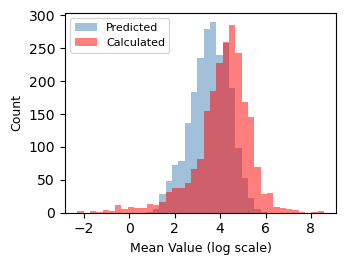

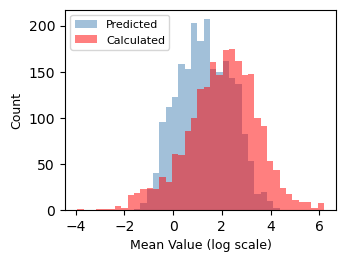

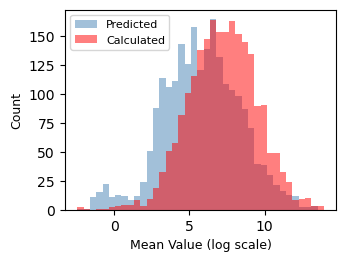

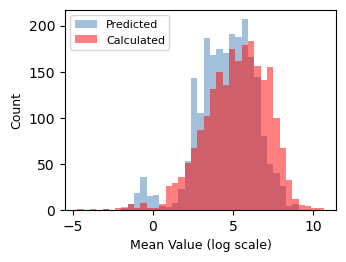

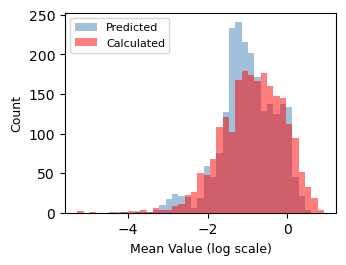

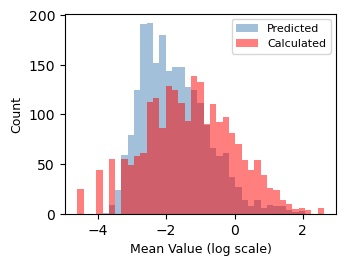

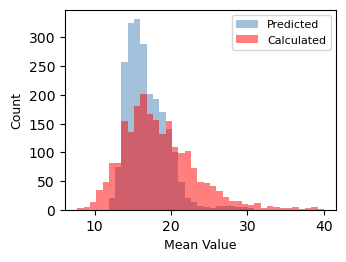

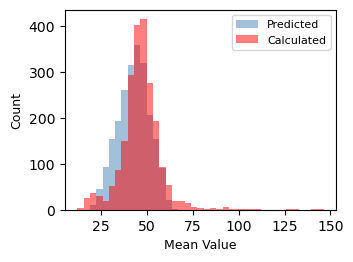

In [18]:
for response in ["LRATIO", "LM", "L_BOL", "MASS", "DIAM", "SURF_DENS", "TEMP", "T_BOL"]:
    data = pd.read_csv(here('predictions', f'{response}_final_predictions.csv'))

    if response == 'TEMP' or response == 'T_BOL':
        pred_data = data['mean_pred']
        phot_data = phot[response]
    else:
        pred_data = np.log(data['mean_pred'])
        phot_data = np.log(phot[response])

    phot_data_sample = phot_data.sample(n=2220, random_state=2026)

    combined_data = np.hstack((pred_data, phot_data_sample))
    bins = np.linspace(min(combined_data), max(combined_data), 40)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    plt.hist(pred_data, bins=bins, color='steelblue', alpha=0.5, label='Predicted')
    plt.hist(phot_data_sample, bins=bins, color='red', alpha=0.5, label='Calculated')

    if response == 'TEMP' or response == 'T_BOL':
        # plt.title(f'{response} Prediction Distribution Comparison')
        plt.xlabel('Mean Value', fontsize=9)
    else:
        # plt.title(f'{response} Log Prediction Distribution Comparison')
        plt.xlabel('Mean Value (log scale)', fontsize=9)
    plt.ylabel('Count', fontsize=9)

    plt.legend(fontsize=8)

    plt.savefig(here('graphing/prediction_intervals/prediction_interval_distributions/v2/comparisons', f'{response}_pred_distribution_comparison_for_paper.png'), dpi=300, bbox_inches="tight")
    plt.show()